# 04 — Logistic Regression
Logistic Regression models the log-odds of the positive class (`unstable`) as a linear function of
the standardised features and is trained by minimising log-loss with L2 regularisation
(scikit-learn default `C = 1.0`). It is an interpretable **linear baseline**.

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable when running from notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "electrical_grid_stability.csv"

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
%matplotlib inline

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from src.preprocessing import FEATURE_COLUMNS, load_and_split_data
from src.train_models import get_logistic_regression_pipeline
from src.evaluation import evaluate_predictions

X_train, X_test, y_train, y_test = load_and_split_data(DATA_PATH)
lr = get_logistic_regression_pipeline()
lr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(lr, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"], return_train_score=True)
pd.DataFrame(cv_res).drop(columns=["fit_time", "score_time"]).agg(["mean", "std"]).round(4)

,test_accuracy,train_accuracy,test_f1_macro,train_f1_macro
mean,0.8146,0.8144,0.7956,0.7952
std,0.0081,0.0022,0.0089,0.0025


**Interpretation:** cross-validation accuracy (≈ 0.81) and train-fold accuracy are almost equal, so the linear model is **not overfitting** — its errors come from bias (a linear boundary is too simple), not variance.

In [4]:
lr.fit(X_train, y_train)
res = evaluate_predictions(y_test, lr.predict(X_test))
print(res["classification_report"])
print("Confusion matrix (rows = actual, cols = predicted; order: stable, unstable)")
print(res["confusion_matrix"])

              precision    recall  f1-score   support

      stable     0.7774    0.7044    0.7391       724
    unstable     0.8408    0.8856    0.8626      1276

    accuracy                         0.8200      2000
   macro avg     0.8091    0.7950    0.8009      2000
weighted avg     0.8178    0.8200    0.8179      2000

Confusion matrix (rows = actual, cols = predicted; order: stable, unstable)
[[ 510  214]
 [ 146 1130]]


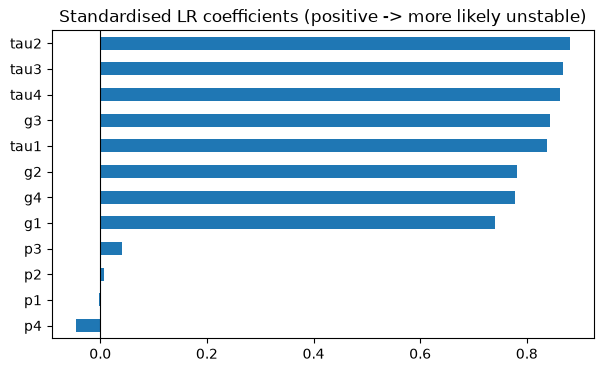

p4     -0.045
p1     -0.002
p2      0.007
p3      0.042
g1      0.741
g4      0.778
g2      0.782
tau1    0.837
g3      0.844
tau4    0.862
tau3    0.868
tau2    0.880
dtype: float64

In [5]:
coef = pd.Series(lr.named_steps["classifier"].coef_[0], index=FEATURE_COLUMNS)
coef.sort_values().plot.barh(figsize=(7, 4), title="Standardised LR coefficients (positive -> more likely unstable)")
plt.axvline(0, color="black", lw=0.8); plt.show()
coef.round(3).sort_values()

**Interpretation:**
- Test accuracy is **82.0%**, well above the 63.8% baseline, but 146 unstable grids are predicted as
  stable (missed instabilities) and 214 stable grids are flagged as unstable.
- Positive `tau` and `g` coefficients agree with the EDA: longer delays and stronger price reaction
  increase the odds of instability. The `p` coefficients are small.
- Because `p1` is an exact linear combination of `p2`–`p4`, the individual `p` coefficients are not
  uniquely identifiable — L2 regularisation picks one of infinitely many equivalent solutions — so
  they should not be interpreted individually.
- The underlying stability condition depends on **products** of parameters (e.g., delay × elasticity),
  which a linear boundary cannot represent. Notebook 07 tests adding interaction terms.